# Perte de CA réalisée : mesurer la vraie décote du churn total

**Question.** Le doc applique une décote d'environ 12 % au CA du churn total, parce que ces clients « reviennent dans les 3 mois ». Mais un client qui revient après 250 jours a quand même perdu 250 jours de CA : le compter comme non perdu est trop sévère. Quelle part du CA du churn total est **réellement** perdue ? Et que pèsent, en plus, les clients que le label à 180 jours ne voit pas (silences puis retour, baisses) ?

**Mesure directe, client par client.** À la date de photo T :

- `V` = CA des 180 jours avant T × 2 (CA annualisé, comme dans le doc) ;
- `R` = CA réellement acheté pendant les **360 jours** après T (deux fenêtres de 180 jours, cohérent avec le × 2) ;
- **perte réalisée** `ℓ = max(0, V − R)`.

Une seule photo reste observable sur 360 jours à chaque date : les photos du 22/03/2023 au 22/09/2023 (7 photos mensuelles, 360 jours de recul tiennent encore dans les données).

**Saison.** `V` annualise 6 mois alors que `R` couvre une année pleine ; la saison est déjà traitée dans le doc (facteur de 0,94 à 1,43 sur la marge), on ne la double pas ici. Une correction par un indice global `ΣR / ΣV` serait biaisée, car cet indice contient les pertes elles-mêmes. Les ratios ci-dessous restent donc **bruts**.

**Trois lectures.** A : la population du churn total (décote réelle). B : d'où vient la perte réalisée sur tout le périmètre (total, partiel, autres). C : la même décote **sur la liste de K clients** classée par un score hors échantillon, plus le CA manqué par des clients que le label à 180 jours ne compte pas.

Périmètre du dataset, montants annualisés en M€, non extrapolés. Dates d'origine du dataset.

In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "1"        # reproductibilité
from pathlib import Path
import time
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import GroupKFold

pd.set_option("display.max_columns", 50, "display.width", 220, "display.float_format", lambda x: f"{x:,.3f}")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PARQUET = ROOT / "data" / "sales.parquet"
con = duckdb.connect()
con.execute("SET memory_limit='4GB'")
con.execute(f"SET temp_directory='{ROOT / 'data' / '.duckdb_tmp'}'")


def q(sql):
    return con.execute(sql).fetchdf()


C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a")
INK, INK2, MUTED, GRID, SURF = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
plt.rcParams.update({"axes.facecolor": SURF, "figure.facecolor": SURF, "axes.edgecolor": "#c3c2b7", "axes.grid": True,
                     "grid.color": GRID, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

HIST, MIN_PURCH, MED_GAP_MAX, ANN = 180, 6, 30, 2
WIN = 360                                   # fenêtre de CA réalisé (2 x 180 jours)
DATES = [pd.Timestamp("2023-03-22") + pd.DateOffset(months=j) for j in range(7)]   # 22/03 -> 22/09/2023
K_LIST = (700, 2000)
N_BOOT, SEED = 200, 0

In [2]:
t0 = time.time()
con.execute(f"CREATE OR REPLACE VIEW sales AS SELECT * FROM read_parquet('{PARQUET}')")
con.execute("""
CREATE OR REPLACE TABLE bn AS
SELECT client_id, date_order AS d, sum(sales_net) AS rev
FROM sales WHERE date_order BETWEEN DATE '2022-09-22' AND DATE '2024-09-22'
GROUP BY 1, 2 HAVING sum(sales_net) > 0.01""")
DATA_END = pd.Timestamp(q("SELECT max(d) AS m FROM bn").iloc[0, 0])
assert max(DATES) + pd.Timedelta(days=WIN) <= DATA_END
print(f"fin des données {DATA_END:%d/%m/%Y} · dernière photo observable sur {WIN} j : {max(DATES):%d/%m/%Y} · {time.time() - t0:.0f}s")

fin des données 22/09/2024 · dernière photo observable sur 360 j : 22/09/2023 · 2s


In [3]:
FEATS = ["recency_days", "freq_180d", "freq_90d", "freq_prev_90d", "rev_180d", "rev_90d", "rev_prev_90d",
         "gap_median", "gap_p90", "recency_ratio", "freq_trend", "rev_trend"]


def photo(T):
    t = f"{T:%Y-%m-%d}"
    df = q(f"""
    WITH hist AS (SELECT client_id, d, rev, d - lag(d) OVER (PARTITION BY client_id ORDER BY d) AS gap
                  FROM bn WHERE d < DATE '{t}' AND d >= DATE '{t}' - {HIST}),
    agg AS (SELECT client_id, count(*) AS freq_180d, median(gap) AS gap_median, quantile_cont(gap, 0.9) AS gap_p90,
                   max(d) AS last_d, sum(rev) AS rev_180d,
                   count(*) FILTER (WHERE d >= DATE '{t}' - 90) AS freq_90d,
                   count(*) FILTER (WHERE d <  DATE '{t}' - 90) AS freq_prev_90d,
                   coalesce(sum(rev) FILTER (WHERE d >= DATE '{t}' - 90), 0) AS rev_90d,
                   coalesce(sum(rev) FILTER (WHERE d <  DATE '{t}' - 90), 0) AS rev_prev_90d
            FROM hist GROUP BY 1),
    fut AS (SELECT client_id, min(d) - DATE '{t}' AS next_gap,
                   coalesce(sum(rev) FILTER (WHERE d < DATE '{t}' + 180), 0) AS rev_b,
                   sum(rev) AS rev_next
            FROM bn WHERE d >= DATE '{t}' AND d < DATE '{t}' + {WIN} GROUP BY 1)
    SELECT a.*, date_diff('day', a.last_d, DATE '{t}') AS recency_days, f.next_gap, coalesce(f.rev_b, 0) AS rev_b,
           coalesce(f.rev_next, 0) AS rev_next
    FROM agg a LEFT JOIN fut f USING (client_id)""")
    df["next_gap"] = df.next_gap.astype(float)
    df = df[(df.freq_180d >= MIN_PURCH) & (df.gap_median <= MED_GAP_MAX)].sort_values("client_id").copy()
    df["V"] = ANN * df.rev_180d
    df["recency_ratio"] = df.recency_days / df.gap_p90.clip(lower=1)
    df["freq_trend"] = df.freq_90d / (df.freq_prev_90d + 1)
    df["rev_trend"] = df.rev_90d / (df.rev_prev_90d + 1)
    df["seg"] = np.where(df.gap_median <= 7, "Rapide", "Moyen")
    df["gone"] = (df.next_gap.isna() | (df.next_gap >= 180)).astype(int)            # aucun achat pendant 180 j
    df["back90"] = (df.gone.eq(1) & df.next_gap.lt(270)).astype(int)                   # revient dans les 90 j après la fenêtre
    df["partial"] = (df.gone.eq(0) & (df.rev_b < 0.5 * df.rev_180d)).astype(int)
    df["group"] = np.select([df.gone.eq(1), df.partial.eq(1)], ["Total (aucun achat à 180 j)", "Partiel (CA divisé par plus de 2)"],
                            default="Autres clients")
    df["loss"] = (df.V - df.rev_next).clip(lower=0)                                     # perte réalisée, brute
    df["T"] = T
    return df.reset_index(drop=True)


t0 = time.time()
PH = {T: photo(T) for T in DATES}
print(f"{len(PH)} photos en {time.time() - t0:.0f}s")

7 photos en 1s


## A. Décote réelle du churn total

Pour les clients du churn total (aucun achat pendant 180 jours) : part de leur valeur `V` qui est **réellement perdue** sur 360 jours, et combien reviennent. La colonne « revient dans les 90 j » reprend la mesure du doc (lemme 2), à titre de contrôle.

In [4]:
rows = []
for T, d in PH.items():
    g = d[d.gone == 1]
    rows.append({"Photo": f"{T:%d/%m/%Y}", "Clients du total": len(g), "CA du total, V (M)": g.V.sum() / 1e6,
                 "Revient dans les 90 j (% de V)": 100 * g.V[g.back90 == 1].sum() / g.V.sum(),
                 "Revient à 360 j (% de V)": 100 * g.V[g.rev_next > 0].sum() / g.V.sum(),
                 "R / V (%)": 100 * g.rev_next.sum() / g.V.sum(),
                 "Perte réalisée (% de V)": 100 * g.loss.sum() / g.V.sum(),
                 "Décote réelle (% de V)": 100 - 100 * g.loss.sum() / g.V.sum()})
tabA = pd.DataFrame(rows).set_index("Photo")
tabA

,Clients du total,"CA du total, V (M)",Revient dans les 90 j (% de V),Revient à 360 j (% de V),R / V (%),Perte réalisée (% de V),Décote réelle (% de V)
Photo,,,,,,,
22/03/2023,2379,59.842,11.137,15.515,3.173,97.398,2.602
22/04/2023,2382,74.883,10.010,13.817,3.457,97.242,2.758
22/05/2023,2051,60.533,8.734,11.842,2.881,97.798,2.202
22/06/2023,2031,60.401,7.602,17.251,1.887,98.445,1.555
22/07/2023,2128,60.769,14.325,17.172,1.922,98.370,1.630
22/08/2023,2234,56.906,11.304,15.092,2.896,97.747,2.253
22/09/2023,2410,65.302,9.860,14.178,3.316,97.000,3.000


In [5]:
POOL = pd.concat(PH.values(), ignore_index=True)
G = POOL[POOL.gone == 1]
rows = []
for name, sub in (("Rapides + moyens", G), ("Rapides", G[G.seg == "Rapide"]), ("Moyens", G[G.seg == "Moyen"])):
    rows.append({"Segment": name, "Clients × photos": len(sub), "V (M, 7 photos)": sub.V.sum() / 1e6,
                 "Revient dans les 90 j (% de V)": 100 * sub.V[sub.back90 == 1].sum() / sub.V.sum(),
                 "Revient à 360 j (% de V)": 100 * sub.V[sub.rev_next > 0].sum() / sub.V.sum(),
                 "R / V des clients qui reviennent (%)": 100 * sub.rev_next[sub.rev_next > 0].sum() / sub.V[sub.rev_next > 0].sum(),
                 "Perte réalisée (% de V)": 100 * sub.loss.sum() / sub.V.sum(),
                 "Décote réelle (% de V)": 100 - 100 * sub.loss.sum() / sub.V.sum()})
pd.DataFrame(rows).set_index("Segment")

,Clients × photos,"V (M, 7 photos)",Revient dans les 90 j (% de V),Revient à 360 j (% de V),R / V des clients qui reviennent (%),Perte réalisée (% de V),Décote réelle (% de V)
Segment,,,,,,,
Rapides + moyens,15615,438.635,10.399,14.933,18.857,97.691,2.309
Rapides,9804,368.076,8.358,12.265,16.320,98.375,1.625
Moyens,5811,70.560,21.046,28.853,24.483,94.126,5.874


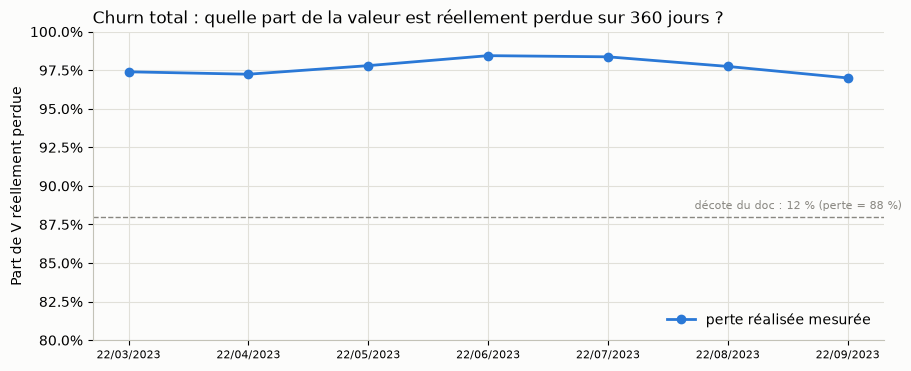

In [6]:
fig, ax = plt.subplots(figsize=(9, 3.6), constrained_layout=True)
x = np.arange(len(tabA))
ax.plot(x, tabA["Perte réalisée (% de V)"], "o-", color=C["blue"], lw=2, label="perte réalisée mesurée")
ax.axhline(88, color=MUTED, ls="--", lw=1)
ax.text(len(x) - 0.55, 88.5, "décote du doc : 12 % (perte = 88 %)", color=MUTED, fontsize=8, ha="right")
ax.set_xticks(x)
ax.set_xticklabels(tabA.index, fontsize=8)
ax.set_ylim(80, 100)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_ylabel("Part de V réellement perdue")
ax.set_title("Churn total : quelle part de la valeur est réellement perdue sur 360 jours ?", loc="left")
ax.legend(frameon=False, loc="lower right")
plt.show()

## B. D'où vient la perte réalisée sur tout le périmètre ?

La perte réalisée `ℓ` additionnée sur **tous** les réguliers, par groupe. Le groupe « Total » est celui du label à 180 jours ; « Partiel » (CA(B) < 50 % de CA(A)) et « Autres » sont des clients que ce label ne compte pas. Attention : `max(0, ·)` compte aussi les fluctuations normales (les clients qui baissent un peu), donc le groupe « Autres » contient du bruit : son taux moyen sert de repère. Les M€ de 7 photos cumulées ne s'additionnent pas dans le temps (les fenêtres de 360 jours se chevauchent) ; seuls les ratios se lisent.

In [7]:
rows = []
tot_loss, tot_V = POOL.loss.sum(), POOL.V.sum()
for gname in ("Total (aucun achat à 180 j)", "Partiel (CA divisé par plus de 2)", "Autres clients"):
    sub = POOL[POOL.group == gname]
    rows.append({"Groupe": gname, "Clients × photos": len(sub), "V (% du total)": 100 * sub.V.sum() / tot_V,
                 "Perte réalisée (M, 7 photos cumulées)": sub.loss.sum() / 1e6,
                 "Part de la perte réalisée (%)": 100 * sub.loss.sum() / tot_loss,
                 "Perte réalisée / V (%)": 100 * sub.loss.sum() / sub.V.sum()})
tabB = pd.DataFrame(rows).set_index("Groupe")
print(f"CA vrai de référence (valeur V) sur 7 photos : {tot_V / 1e6:,.0f} M ; perte réalisée totale {tot_loss / 1e6:,.0f} M ({100 * tot_loss / tot_V:.1f} % de V)")
tabB

CA vrai de référence (valeur V) sur 7 photos : 29,719 M ; perte réalisée totale 6,493 M (21.8 % de V)


,Clients × photos,V (% du total),"Perte réalisée (M, 7 photos cumulées)",Part de la perte réalisée (%),Perte réalisée / V (%)
Groupe,,,,,
Total (aucun achat à 180 j),15615,1.476,428.509,6.599,97.691
Partiel (CA divisé par plus de 2),93729,15.620,"2,998.040",46.171,64.583
Autres clients,312650,82.904,"3,066.858",47.230,12.448


## C. La même mesure sur la liste de K clients

Scores **hors échantillon** : modèle HistGradientBoosting (12 variables, label « aucun achat à 180 jours »), validation croisée en 5 plis **groupés par client** sur les 7 photos empilées. Limite : les plis ne respectent pas l'ordre du temps (un score de mars peut venir d'un modèle qui a vu des photos de septembre) ; c'est suffisant pour comparer la perte réalisée de la liste, pas pour mesurer la performance du modèle. Liste de K clients par photo, classée par `p × V`. Les M€ sont cumulés sur 7 photos aux fenêtres qui se chevauchent : seuls les ratios se lisent.

In [8]:
POOL = POOL.reset_index(drop=True)
y = POOL.gone.to_numpy()
oof = np.zeros(len(POOL))
for tr, te in GroupKFold(n_splits=5).split(POOL, y, groups=POOL.client_id):
    m = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.08, early_stopping=False, random_state=SEED)
    m.fit(POOL.loc[tr, FEATS], y[tr])
    oof[te] = m.predict_proba(POOL.loc[te, FEATS])[:, 1]
POOL["p"] = oof
POOL["ve"] = POOL.p * POOL.V
print("scores hors échantillon calculés")

scores hors échantillon calculés


In [9]:
rng = np.random.default_rng(SEED)
res = {}
rows = []
for K in K_LIST:
    lists = []
    for T, d in POOL.groupby("T"):
        lists.append(d.nlargest(K, "ve"))
    L = pd.concat(lists)
    gone = L[L.gone == 1]
    rest = L[L.gone == 0]
    boot = []
    n = len(L)
    for _ in range(N_BOOT):
        b = L.iloc[rng.integers(0, n, n)]
        bg = b[b.gone == 1]
        boot.append(1 - bg.loss.sum() / bg.V.sum())
    lo, hi = np.percentile(boot, [2.5, 97.5])
    base_rest = POOL[POOL.gone == 0]
    rows.append({
        "K par photo": K, "Clients × photos": len(L), "Vrais partants dans la liste (%)": 100 * len(gone) / len(L),
        "CA vraiment parti de la liste, V (M)": gone.V.sum() / 1e6,
        "Perte réalisée de ces partants (M)": gone.loss.sum() / 1e6,
        "Décote réelle sur la liste (% de V)": 100 * (1 - gone.loss.sum() / gone.V.sum()),
        "IC 95 % de la décote (%)": f"[{100 * lo:.0f}–{100 * hi:.0f}]",
        "Perte réalisée des non-partants de la liste (M)": rest.loss.sum() / 1e6,
        "… taux (% de leur V)": 100 * rest.loss.sum() / rest.V.sum(),
        "… même taux, tous les non-partants (% de leur V)": 100 * base_rest.loss.sum() / base_rest.V.sum(),
        "Excès de perte des non-partants de la liste (M)": (rest.loss.sum() - rest.V.sum() * base_rest.loss.sum() / base_rest.V.sum()) / 1e6,
        "… en % du CA vraiment parti de la liste": 100 * (rest.loss.sum() - rest.V.sum() * base_rest.loss.sum() / base_rest.V.sum()) / gone.V.sum(),
    })
tabC = pd.DataFrame(rows).set_index("K par photo").T
tabC

K par photo,700,2000
Clients × photos,4900,14000
Vrais partants dans la liste (%),45.878,31.400
"CA vraiment parti de la liste, V (M)",217.013,278.370
Perte réalisée de ces partants (M),215.164,275.431
Décote réelle sur la liste (% de V),0.852,1.056
IC 95 % de la décote (%),[0–2],[1–2]
Perte réalisée des non-partants de la liste (M),242.102,504.411
… taux (% de leur V),47.188,41.719
"… même taux, tous les non-partants (% de leur V)",20.713,20.713
Excès de perte des non-partants de la liste (M),135.831,253.974


## Conclusions

1. **Décote réelle du churn total : environ 2 %, loin des 12 % du doc.** Sur 7 photos, les clients du churn total perdent en moyenne **97,7 % de leur valeur `V`** sur 360 jours (de 97,0 à 98,4 % selon la photo), soit une décote de 2,3 % (1,6 à 3,0 %). Rapides : 1,6 %. Moyens : 5,9 %.
2. **Les 12 % « reviennent » sont exacts, mais ils reprennent très peu.** 10,4 % de `V` appartient à des clients qui reviennent dans les 90 jours après la fenêtre (le doc : 12 %). Mais sur les 360 jours, ces clients n'achètent que **19 % de leur valeur** (rapides 16 %, moyens 24 %) : ils reviennent tard, et peu. Retirer 12 % du CA surestime donc la décote d'un facteur 5. La mesure à 360 jours ne voit pas les retours plus tardifs, qui valent moins encore dans la fenêtre.
3. **Sur la liste de K clients, la décote est plus faible encore : ≈ 1 %** (0,9 % à K = 700 [0–2], 1,1 % à K = 2 000 [1–2]). Les vrais partants classés par le modèle perdent près de 99 % de leur valeur.
4. **La liste capte aussi de la perte que le label à 180 jours ne compte pas.** Parmi les clients de la liste qui ne sont pas « partis », la perte réalisée est de 47 % de leur `V` à K = 700 (42 % à K = 2 000), contre 21 % pour tous les non-partants. L'excès représente 63 % (K = 700) à 91 % (K = 2 000) du CA des vrais partants de la liste. C'est le groupe des baisses de CA que traite le churn partiel ; ce CA n'est pas démontré sauvable, et il dépend de la rétention.
5. **Sur tout le périmètre**, le groupe « Total » pèse 1,5 % de `V` mais 6,6 % de la perte réalisée ; le « Partiel » 15,6 % de `V` pour 46 % de la perte (65 % de leur `V`) ; le groupe « Autres » 83 % de `V` pour 47 % de la perte, à 12,4 % de leur `V` : surtout les fluctuations normales du CA, à ne pas lire comme une perte.

**Conséquence pour les marges.** Le CA du churn total est une très bonne mesure du CA réellement perdu (≈ 98 %), contrairement à ce que laisse penser la décote de 12 % du doc. La décote à retenir est de **2 % (rapides) à 6 % (moyens), ≈ 2 % au total**, en fourchette de 1 à 6 %.

**Limites.** Photos du 22/03 au 22/09/2023 seulement (360 jours de recul) : une saison, 7 photos aux fenêtres qui se chevauchent, donc des M€ qui ne s'additionnent pas dans le temps. `V` annualise 6 mois alors que `R` couvre une année : la saison n'est pas corrigée ici, elle l'est dans le facteur saison du doc. Les scores de la liste sont hors échantillon par plis groupés par client, sans respecter l'ordre du temps : ils servent à comparer la perte réalisée de la liste, pas à mesurer la performance du modèle. L'excès de perte du point 4 inclut la fluctuation et la régression vers la moyenne : c'est un ordre de grandeur.